images shape: (1797, 8, 8)
labels shape: (1797,)
pehli photo ka label: 0


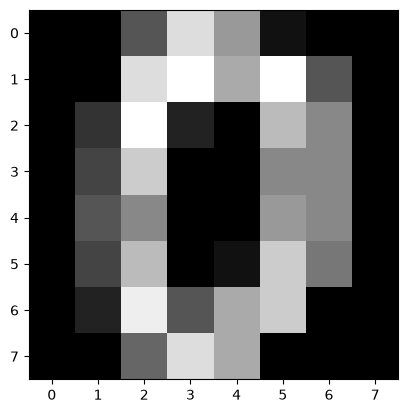

In [1]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

d = load_digits()
print("images shape:", d.images.shape)
print("labels shape:", d.target.shape)
print("pehli photo ka label:", d.target[0])

plt.imshow(d.images[0], cmap="gray")
plt.show()

In [2]:
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

d = load_digits()
X = torch.tensor(d.images / 16.0, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(d.target)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: torch.Size([1437, 1, 8, 8])
X_test : torch.Size([360, 1, 8, 8])


In [3]:
import torch

model = torch.nn.Sequential(
    torch.nn.Flatten(),          # 1×8×8 photo ko 64 numbers ki line bana do
    torch.nn.Linear(64, 10),     # 64 numbers se 10 scores (har digit ka ek)
)

print(sum(p.numel() for p in model.parameters()))

650


In [4]:
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0)

d = load_digits()
X = torch.tensor(d.images / 16.0, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(d.target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(64, 10))
loss_fn = torch.nn.CrossEntropyLoss()                 # naya: classification ki galti
opt = torch.optim.Adam(model.parameters(), lr=0.01)

for step in range(200):
    loss = loss_fn(model(X_train), y_train)
    opt.zero_grad()
    loss.backward()
    opt.step()

with torch.no_grad():
    pred = model(X_test).argmax(dim=1)                # naya: sabse bada score = jawab
acc = (pred == y_test).float().mean().item()
print("loss:", round(loss.item(), 3))
print("test accuracy:", round(acc * 100, 1), "%")

loss: 0.192
test accuracy: 95.3 %


In [5]:
with torch.no_grad():
    train_pred = model(X_train).argmax(dim=1)
train_acc = (train_pred == y_train).float().mean().item()
print("train accuracy:", round(train_acc * 100, 1), "%")


train accuracy: 96.5 %


In [6]:
cnn = torch.nn.Sequential(
    torch.nn.Conv2d(1, 8, kernel_size=3, padding=1),   # 8 filters (3×3), edges dhoondhte hain
    torch.nn.ReLU(),
    torch.nn.MaxPool2d(2),                             # 8×8 se 4×4 (Day 10 wala max pooling)
    torch.nn.Flatten(),                                # 8×4×4 = 128 numbers
    torch.nn.Linear(128, 10),                          # 10 digits ke scores
)

torch.manual_seed(0)
opt = torch.optim.Adam(cnn.parameters(), lr=0.01)
for step in range(200):
    loss = loss_fn(cnn(X_train), y_train)
    opt.zero_grad()
    loss.backward()
    opt.step()

with torch.no_grad():
    test_acc = (cnn(X_test).argmax(dim=1) == y_test).float().mean().item()
print("CNN test accuracy:", round(test_acc * 100, 1), "%")
print("CNN parameters:", sum(p.numel() for p in cnn.parameters())) 


CNN test accuracy: 97.8 %
CNN parameters: 1370
